# 10 · Ejercicios y verificación de los módulos sin broker

[Índice](00_indice_mqtt.ipynb) · [Anterior](09_python_modular.ipynb)

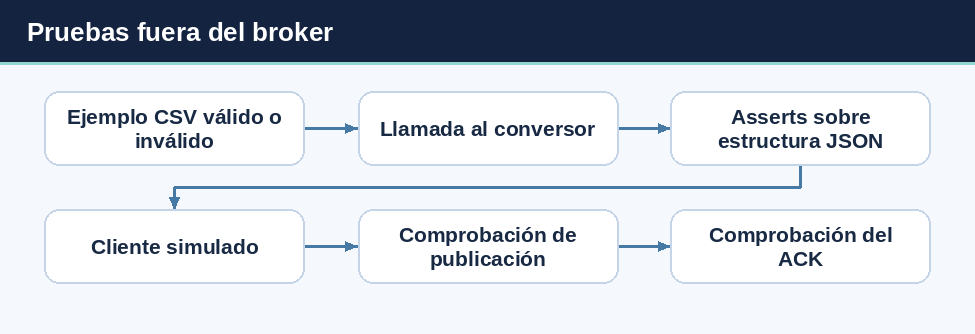

## Cómo ejecutar estos ejercicios

Usa un kernel Python 3.10 o posterior; puedes seleccionar `backend/.venv/bin/python` en tu editor.
Ejecuta las celdas en orden dentro de este notebook. No abren conexiones, no inician el
trabajador infinito y no escriben config.json ni el CSV del ESP32. Usan unittest.mock de
la biblioteca estándar, no un servidor MQTT ni un simulador de hardware.

La primera celda localiza la raíz subiendo desde el directorio del kernel. Agrega esa raíz
a sys.path solo para permitir los imports del ejercicio cuando Jupyter arrancó dentro de
docs/mqtt. La aplicación normal no usa esta modificación. Si el notebook se mueve
fuera del proyecto, usa un directorio de trabajo dentro del repositorio para encontrarlo.

In [ ]:
from pathlib import Path
import json
import sys
from unittest.mock import Mock, patch

current = Path.cwd().resolve()
project_root = next(
    (path for path in (current, *current.parents)
     if (path / "backend/scripts/mqtt_bridge/converter.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Ejecuta el notebook desde la raíz ESP32 o una subcarpeta del proyecto")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from backend.scripts.mqtt_bridge.bridge import CsvMqttBridge
from backend.scripts.mqtt_bridge.cli import parse_arguments
from backend.scripts.mqtt_bridge.converter import convert_csv_message, parse_measurement
from backend.scripts.mqtt_bridge.models import ConvertedReading
from backend.scripts.mqtt_bridge.settings import CSV_COLUMNS, MESSAGE_QUEUE_SIZE, RAW_TOPIC_FILTER

print("Modulos cargados sin crear una conexion MQTT")

## 1. Conversión con datos válidos

Se construye un payload bytes, como el que entrega Paho. Convertir str con encode("utf-8")
es lo inverso de decode dentro del conversor. El resultado no es un diccionario suelto:
es ConvertedReading, que separa datos de transporte (ID de fila) del JSON tratado.
`assert` comprueba las condiciones; si alguna no se cumple levanta AssertionError.

In [ ]:
header = ",".join(CSV_COLUMNS) + "\n"
topic = "dispositivo/ESP32_S3_0001/crudo"
row = "registro-1,ESP32_S3_0001,2026-11-09T00:30:00-06:00,23.4,53,452.7,false\n"
reading = convert_csv_message(topic, (header + row).encode("utf-8"))
document = json.loads(reading.json_payload)

assert isinstance(reading, ConvertedReading)
assert reading.record_id == "registro-1"
assert document["device_id"] == "ESP32_S3_0001"
assert document["measurements"]["gas"] == {
    "sensor": "MQ135", "value": 452.7, "unit": "ppm", "calibrate": False
}
assert "record_id" not in document
print(json.dumps(document, indent=2, ensure_ascii=False))

## 2. Vacíos, ceros y registros rechazados

Una cadena vacía no equivale a cero. El conversor debe conservar 0.0 cuando el dato es "0",
producir None cuando no existe y rechazar NaN/Infinity. La falta de columnas y la discrepancia
del dispositivo son errores, no conversiones a null. El try/except del ejercicio comprueba
que el error esperado existe; si no ocurre, se falla explícitamente.

In [ ]:
assert parse_measurement("") is None
assert parse_measurement("0") == 0.0
empty_row = "registro-2,ESP32_S3_0001,,,,,false\n"
empty_document = json.loads(
    convert_csv_message(topic, (header + empty_row).encode()).json_payload
)
assert empty_document["timestamp"] is None
assert empty_document["measurements"]["temperature"]["value"] is None

invalid_rows = [
    "registro-3,OTRO_ID,,23,53,450,false\n",
    "registro-3,ESP32_S3_0001,,nan,53,450,false\n",
    "registro-3,ESP32_S3_0001,,23,53,inf,false\n",
    "registro-3,ESP32_S3_0001,,23,53,450,desconocido\n",
    "registro-3,ESP32_S3_0001,,23\n",
    "registro-3,ESP32_S3_0001,,23,53,450,false,extra\n",
]
for invalid_row in invalid_rows:
    try:
        convert_csv_message(topic, (header + invalid_row).encode())
    except ValueError:
        continue
    raise AssertionError("Se acepto una fila invalida")
print("Vacios, cero y seis rechazos: correctos")

## 3. Confirmaciones con un doble del cliente

`Mock` permite observar llamadas sin abrir red. Aquí el cliente falso devuelve un objeto
publication falso. `is_published()` define si simulamos un PUBACK recibido o una espera
que no logró confirmar. El test usa la clase real CsvMqttBridge; no llama start y no crea hilos.

Esto comprueba la decisión de enviar el ACK después del resultado de publicación. No comprueba
comportamiento de TCP, broker, librería Paho ni persistencia NVS del hardware.

In [ ]:
for was_confirmed in (False, True):
    client = Mock()
    publication = client.publish.return_value
    publication.is_published.return_value = was_confirmed
    bridge = CsvMqttBridge(client)
    bridge.publish_reading(reading)

    calls = client.publish.call_args_list
    assert calls[0].args == (
        "dispositivo/ESP32_S3_0001/tratado", reading.json_payload
    )
    assert calls[0].kwargs == {"qos": 1}
    publication.wait_for_publish.assert_called_once_with(timeout=10)
    assert len(calls) == (2 if was_confirmed else 1)
    if was_confirmed:
        assert calls[1].args == (
            "dispositivo/ESP32_S3_0001/ack", reading.record_id
        )
        assert calls[1].kwargs == {"qos": 1}
print("ACK solo tras confirmar la publicacion: correcto")

## 4. Callbacks, cola y reconexión

El callback on_message no convierte ni publica inmediatamente: solo encola. Se consulta el
elemento con get_nowait y se equilibra task_done. Después se llena una cola aislada para
comprobar que on_message no bloquea si se alcanza su capacidad. La advertencia de cola llena
es esperada. El último callback simula conexión exitosa y comprueba la suscripción.

In [ ]:
client = Mock()
bridge = CsvMqttBridge(client)
message = Mock(topic=topic, payload=(header + row).encode())
assert client.on_message == bridge.on_message
assert client.on_connect == bridge.on_connect

bridge.on_message(client, None, message)
assert bridge.messages.get_nowait() == (message.topic, message.payload)
bridge.messages.task_done()
client.publish.assert_not_called()

for _ in range(MESSAGE_QUEUE_SIZE):
    bridge.messages.put_nowait((topic, b"ejemplo"))
bridge.on_message(client, None, message)
assert bridge.messages.qsize() == MESSAGE_QUEUE_SIZE
client.publish.assert_not_called()

bridge.on_connect(client, None, None, 0, None)
client.subscribe.assert_called_once_with(RAW_TOPIC_FILTER, qos=1)
print("Cola, callbacks y suscripcion: correctos")

## 5. Argumentos sin lanzar el servicio

`patch.object(sys,"argv",...)` cambia temporalmente los argumentos visibles por argparse.
El with garantiza que se restauran al terminar. No se llama main ni se importa Paho en ejecución.
Así se prueba la interfaz de terminal sin conectarse a localhost.

In [ ]:
with patch.object(sys, "argv", ["csv_to_json.py"]):
    arguments = parse_arguments()
    assert arguments.host == "localhost"
    assert arguments.port == 1883

with patch.object(sys, "argv", ["csv_to_json.py", "--host", "127.0.0.1", "--port", "1884"]):
    arguments = parse_arguments()
    assert arguments.host == "127.0.0.1"
    assert arguments.port == 1884
print("Argumentos predeterminados y explicitos: correctos")

## Verificación real y límites de estos ejercicios

Para la prueba real necesitas Mosquitto activo y una sola instancia del conversor:

```bash
backend/.venv/bin/python backend/scripts/csv_to_json.py --host 127.0.0.1 --port 1883
```

En otra terminal puedes observar `dispositivo/+/tratado`. Las lecturas actuales del ESP32
no requieren Python; las filas históricas sí pasan por su conversión. Ver JSON no demuestra
por sí solo que se borró el CSV: busca el mensaje de borrado en Serial del ESP32.

| Síntoma | Módulo/capa que revisar | Evidencia útil |
|---|---|---|
| No module named paho | Entorno Python | Ejecutable .venv y pip show paho-mqtt. |
| Import relativo sin paquete | Forma de arranque | Usa csv_to_json.py o -m backend.scripts.csv_to_json. |
| Conexión rechazada | Broker y CLI | Host/puerto correctos, broker escuchando. |
| CSV no procesado | converter | Cabecera, ID del topic, campos y UTF-8. |
| Sin confirmación del broker | bridge/transporte | PUBACK de la publicación tratada. |
| CSV se reenvía | Cadena ACK y firmware | ID recibido, persistencia del cursor, registros pendientes. |
| JSON repetido | Reintentos o dos conversores | ACK perdido o dos instancias con la misma suscripción. |

Los notebooks documentan el código actual y no se regeneran automáticamente al editar módulos.
Tras cambiar el contrato ejecuta de nuevo los ejercicios relevantes y actualiza ejemplos y firmware.

[Índice](00_indice_mqtt.ipynb) · [Anterior](09_python_modular.ipynb)